In [1]:
import os
import cv2
import json
import numpy as np
import onnxruntime as ort
import matplotlib.pyplot as plt

from tqdm import tqdm
from glob import glob
from pathlib import Path
from natsort import natsorted
from Config import COLOR_DICT
from scipy.special import softmax

from Exporter import PageXMLExporter
from Source.Utils import unpatch_prediction, pad_image, patch_image, prepare_img_patches, create_dir, resize_to_width, Bbox, LineData, LayoutData, rotate_from_hough

In [2]:
def show_image(image: np.array, cmap: str = "") -> None:
    plt.figure(figsize=(18, 9))
    #plt.axis("off")
    
    if cmap != "":
        plt.imshow(image, cmap=cmap)
    else:
        plt.imshow(image)

In [3]:
layout_config = "D:/Datasets/Tibetan/LayoutAnalysis\TrainingSets/january_v1/512/2024-1-9_12-44/model_config.json"
#layout_inference = LayoutDetection(config_file=layout_config)

In [4]:
#data_path = "D:/Data/LayoutAnalysis/TestData"
#work_path = "W1KG12657_OK"
#volume_path = f"{data_path}/{work_path}"
volume_path = "D:/Datasets/Tibetan/Glomanthang/Volumes/W2KG229028-v14"
images = natsorted(glob(f"{volume_path}/*.jpg"))

print(f"Images: {len(images)}")

Images: 603


(909, 3000, 3)


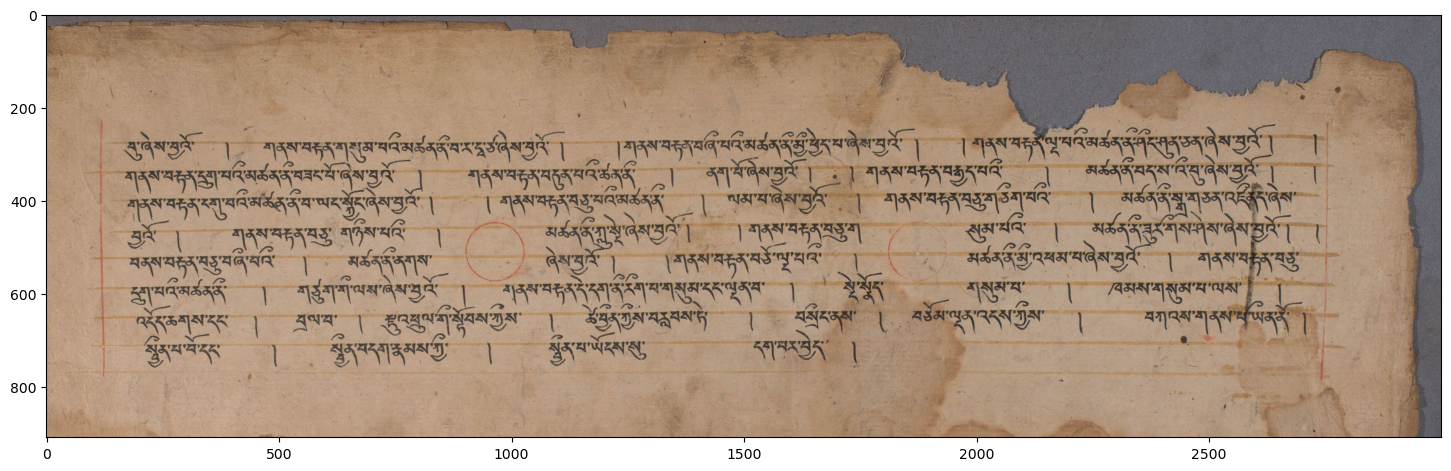

In [5]:
idx = 4
test_img = cv2.imread(images[idx])
test_img = cv2.cvtColor(test_img, cv2.COLOR_BGR2RGB)
print(test_img.shape)
show_image(test_img)

In [6]:
patch_size = 512
_file = open(layout_config)
json_content = json.loads(_file.read())
onnx_model_file = json_content["model"]
print(onnx_model_file)
input_width = json_content["input_width"]
input_height = json_content["input_height"]
class_dict = json_content["classes"]
#model_file_path = f"D:/Data/LayoutAnalysis/Perig/512_v2/2024-1-4_17-17/{onnx_model_file}"
model_file_path = f"D:/Datasets/Tibetan/LayoutAnalysis/TrainingSets/january_v1/512/2024-1-9_12-44/{onnx_model_file}"
#execution_providers = ["CPUExecutionProvider", "CUDAExecutionProvider"]
execution_providers = ["CUDAExecutionProvider"]
layout_inference = ort.InferenceSession(model_file_path, providers=execution_providers)

segmentation_model_gpu.onnx


c:\Users\Eric\miniconda3\envs\pytorch2b\lib\site-packages\onnxruntime\capi\onnxruntime_inference_collection.py:69: UserWarning: Specified provider 'CUDAExecutionProvider' is not in available provider names.Available providers: 'CPUExecutionProvider'
  warnings.warn(


In [9]:
print(ort.__version__)
print(ort.get_available_providers())

1.16.3
['CPUExecutionProvider']


In [10]:
from scipy.special import softmax

def predict_image(image: np.array):

    padded_img, (pad_x, pad_y) = pad_image(image, patch_size, pad_value=0)
    img_patches, y_steps = patch_image(padded_img, patch_size=patch_size)

    img_batch = [prepare_img_patches(x) for x in img_patches]
    img_batch = np.array(img_batch)
    img_batch = np.transpose(img_batch, axes=[0, 3, 1, 2])
    #img_batch = np.expand_dims(img_batch, axis=1)
    #print(f"Input: {img_batch.shape}")
    img_bach = ort.OrtValue.ortvalue_from_numpy(img_batch)
    pred_batch = layout_inference.run(None, {"input": img_batch})
    pred_batch = pred_batch[0]
    pred_batch = np.transpose(pred_batch, axes=[0, 2, 3, 1])
    pred_batch = softmax(pred_batch, axis=-1)

    unpatched_predition = unpatch_prediction(pred_batch, y_splits=y_steps)
    cropped_image = unpatched_predition[: unpatched_predition.shape[0] - pad_y, : unpatched_predition.shape[1] - pad_x]
    # back_sized = cv2.resize(cropped_image, (int(cropped_image.shape[1] / resize_factor), int(cropped_image.shape[0] / resize_factor)))
    back_sized_image = cv2.resize(cropped_image, (image.shape[1], image.shape[0]))

    combined_output = np.argmax(back_sized_image, axis=-1)
    combined_output = combined_output.astype(np.uint8)
    combined_output = np.expand_dims(combined_output, axis=-1)

    return back_sized_image, combined_output

In [11]:
def generate_preview(
    image: np.array, layout_data: LayoutData, alpha: float = 0.4
) -> np.array:
    preview_image = image.copy()
    preview_mask = np.zeros(image.shape, dtype=np.uint8)

    if len(layout_data.lines) > 0:
        color = tuple([int(x) for x in COLOR_DICT["line"].split(",")])

        for line_data in layout_data.lines:
            cv2.drawContours(
                preview_mask,
                [line_data.contour],
                contourIdx=-1,
                color=color,
                thickness=-1,
            )

    if len(layout_data.images) > 0:
        color = tuple([int(x) for x in COLOR_DICT["image"].split(",")])

        for bbox in layout_data.images:
            cv2.rectangle(
                preview_mask,
                (bbox.x, bbox.y),
                (bbox.x + bbox.w, bbox.y + bbox.h),
                color,
                2,
            )

    if len(layout_data.captions) > 0:
        color = tuple([int(x) for x in COLOR_DICT["caption"].split(",")])

        for bbox in layout_data.captions:
            cv2.rectangle(
                preview_mask,
                (bbox.x, bbox.y),
                (bbox.x + bbox.w, bbox.y + bbox.h),
                color,
                2,
            )

    if len(layout_data.margins) > 0:
        color = tuple([int(x) for x in COLOR_DICT["margin"].split(",")])

        for bbox in layout_data.margins:
            cv2.rectangle(
                preview_mask,
                (bbox.x, bbox.y),
                (bbox.x + bbox.w, bbox.y + bbox.h),
                color,
                2,
            )

    cv2.addWeighted(preview_mask, alpha, preview_image, 1 - alpha, 0, preview_image)

    return preview_image

In [12]:
def generate_page_data(predictions: np.array, area_threshold: int = 20) -> np.array:
        
        pred_images = predictions[:, :, 1]
        pred_lines = predictions[:, :, 2]
        pred_margin = predictions[:, :, 3]
        pred_caption = predictions[:, :, 4]

        pred_images = np.where(pred_images > 200, 255, 0)
        pred_lines = np.where(pred_lines > 200, 255, 0)
        pred_margin = np.where(pred_margin > 200, 255, 0)
        pred_caption = np.where(pred_caption > 200, 255, 0)

        pred_images = pred_images.astype(np.uint8)
        pred_lines = pred_lines.astype(np.uint8)
        pred_margin = pred_margin.astype(np.uint8)
        pred_caption = pred_caption.astype(np.uint8)


        images = []
        text_bboxes = []
        lines = []
        captions = []
        margins = []
        

        if np.sum(pred_lines) > 0:
            # TODO: try to identify individual blocks of lines if present
            # TODO: move this step after the filtering of small contours
            x, y, w, h = cv2.boundingRect(np.array(pred_lines))
            bbox = Bbox(x, y, w, h)
            text_bboxes.append(bbox)
        
            contours, _ = cv2.findContours(
                pred_lines, cv2.RETR_LIST, cv2.CHAIN_APPROX_SIMPLE
            )

            """for contour in contours:
                min_rect = cv2.minAreaRect(contour[0])
                box = cv2.boxPoints(min_rect)
                box = np.intp(box)
                lines.append(box)
            """
            filtered_contours = []
            for contour in contours:
                area = cv2.contourArea(contour)

                if area > area_threshold:
                    filtered_contours.append(contour)


            for _, contour in enumerate(filtered_contours):
                x, y, w, h = cv2.boundingRect(contour)
                x_center = x + (w // 2)
                y_center = y + (h // 2)
                
                line_data = LineData(
                    contour=contour,
                    bbox=Bbox(x, y, w, h),
                    center=(x_center, y_center))
                
                lines.append(line_data)


        if np.sum(pred_images) > 0:
            contours, _ = cv2.findContours(
                pred_images, cv2.RETR_LIST, cv2.CHAIN_APPROX_SIMPLE
            )
            
            for contour in contours:
                x, y, w, h = cv2.boundingRect(contour)
                bbox = Bbox(x, y, w, h)
                images.append(bbox)


        if np.sum(pred_margin) > 0:
            contours, _ = cv2.findContours(
                pred_margin, cv2.RETR_LIST, cv2.CHAIN_APPROX_SIMPLE
            )
            
            for contour in contours:
                x, y, w, h = cv2.boundingRect(contour)
                bbox = Bbox(x, y, w, h)
                margins.append(bbox)


        if np.sum(pred_caption) > 0:
            contours, _ = cv2.findContours(
                pred_caption, cv2.RETR_LIST, cv2.CHAIN_APPROX_SIMPLE
            )

            for contour in contours:
                x, y, w, h = cv2.boundingRect(contour)
                bbox = Bbox(x, y, w, h)
                captions.append(bbox)
            

        layout_data = LayoutData(images, text_bboxes, lines, captions, margins)

        return layout_data

In [13]:
idx = 25
image_name = os.path.basename(images[idx]).split(".")[0]
test_img = cv2.imread(images[idx])
test_img = resize_to_width(test_img, target_width=2048)
test_img = cv2.cvtColor(test_img, cv2.COLOR_BGR2RGB)
test_img, angle = rotate_from_hough(test_img)

test_prediction, class_image = predict_image(test_img)
test_prediction = test_prediction.astype(np.uint8)
layout_data = generate_page_data(test_prediction, area_threshold=5)

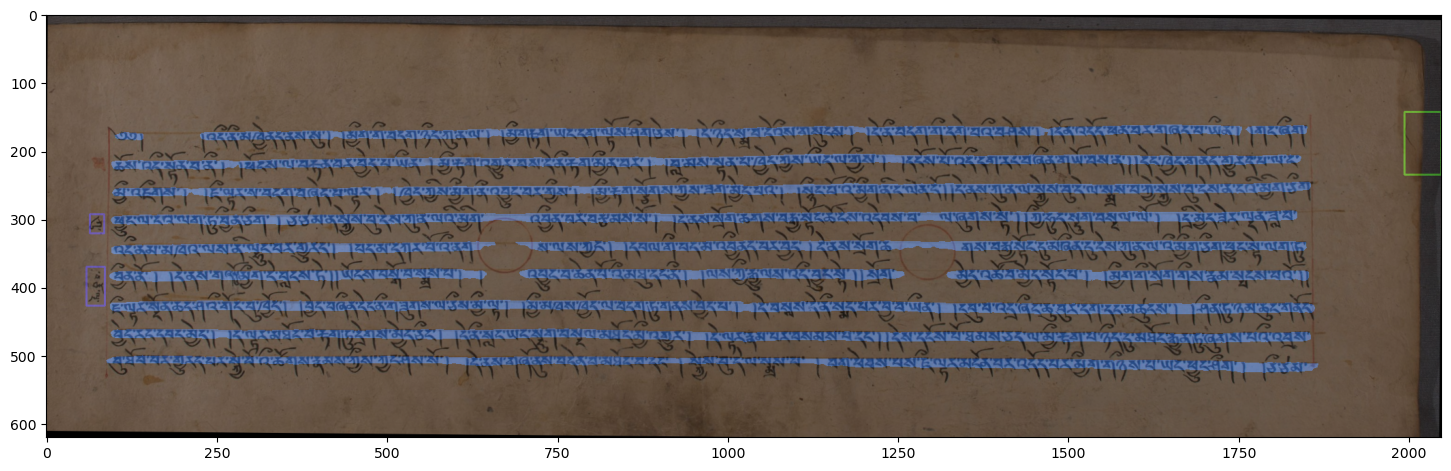

In [14]:
preview_img = generate_preview(test_img, layout_data)
show_image(preview_img)

In [15]:
def get_line_treshold(line_prediction: np.array, slice_width: int = 20, steps: int = 8):
    """
    This function generates n slices (of n = steps) width the width of slice_width across the bbox of the detected lines.
    The slice with the max. number of contained contours is taken to be the canditate to calculate the bbox center of each contour and
    take the median distance between each bbox center as estimated line cut-off threshold to sort each line segment across the horizontal

    Note: This approach might turn out to be problematic in case of sparsely spread line segments across a page
    """
    
    slice_width = 20
    steps = 8
    x, y, w, h = cv2.boundingRect(line_prediction)
    bbox_width = w - x
    x_steps = (bbox_width // steps) - 1 - slice_width

    bbox_numbers = []

    for step in range(1, steps+1):
        x_offset = x_steps * step
        x_start = x+x_offset
        x_end = x_start+slice_width
        #print(f"{x_start}:{x_end}")

        slice = line_prediction[y:y+h, x_start:x_end]
        contours, _ = cv2.findContours(
                    slice, cv2.RETR_LIST, cv2.CHAIN_APPROX_SIMPLE
                )
        #bbox = cv2.boundingRect(contour)
        bbox_numbers.append((len(contours), contours))

    sorted_list = sorted(bbox_numbers, key = lambda x : x[0], reverse=True)
    reference_slice = sorted_list[0]

    y_points = []
    n_contours, contours = reference_slice

    for _, contour in enumerate(contours):
        x, y, w, h  = cv2.boundingRect(contour)
        #x_center = x + (w // 2)
        y_center = y + (h // 2)
        y_points.append(y_center)
        
    
    line_threshold = np.median(y_points) // n_contours
    print(f"line_treshold: {line_threshold}")

    return line_threshold

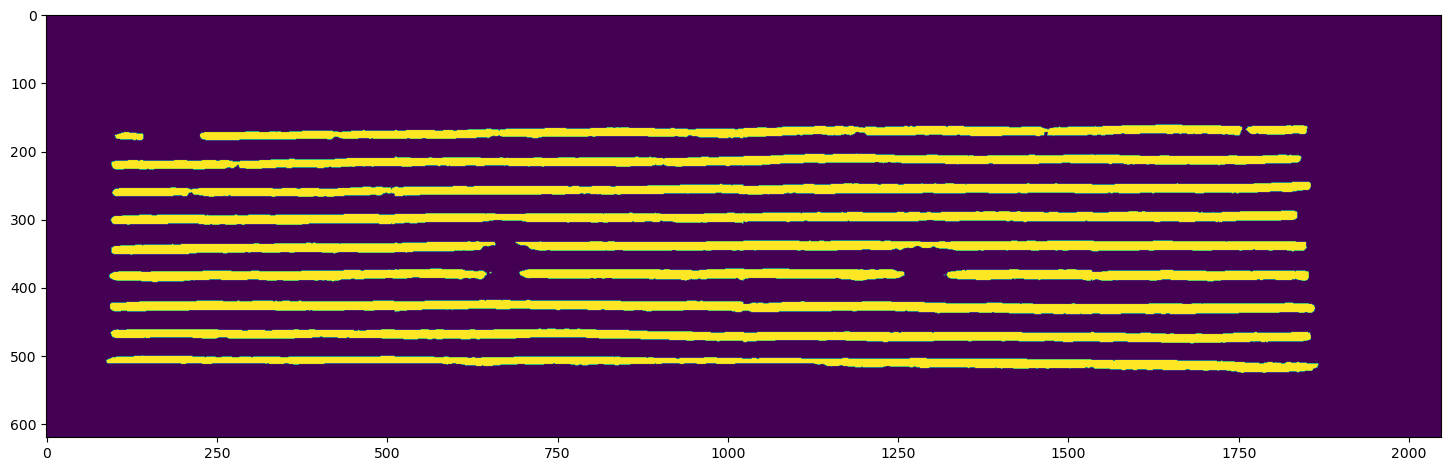

In [16]:
pred_lines = test_prediction[:, :, 2]
pred_lines = np.where(pred_lines > 200, 255, 0)

show_image(pred_lines)

In [17]:
def get_line_bbox_centers(layout_data: LayoutData) -> list[tuple[int, int]]:
    centers = []

    for line in layout_data.lines:
        x_center = line.bbox.x + (line.bbox.w // 2)
        y_center = line.bbox.y + (line.bbox.h // 2)
       
        centers.append((x_center, y_center))

    return centers

In [18]:
def group_bbox_centers(bbox_centers: list[tuple[int, int]], line_threshold: int = 20):
  
  sorted_bbox_centers = []
  tmp_line = []

  for i in range(0, len(bbox_centers)):
    # print(f"{i} -> {bbox_centers[i]}")
    
      if len(tmp_line) > 0:
        for s in range(0, len(tmp_line)):
          # is box on same line?
          y_diff = abs(tmp_line[s][1] - bbox_centers[i][1])

          # found new line?
          if y_diff > line_threshold:
            tmp_line.sort(key=lambda x:x[0])
            #print(f"Adding line: {tmp_line}")
            sorted_bbox_centers.append(tmp_line.copy())
            tmp_line.clear()
            #print(f"{i} -> cleared tmp_list: starting new tmp line: {bbox_centers[i]}")
            tmp_line.append(bbox_centers[i])
            break
          else:
          # print(f"{i} -> below thresh: appending to tmp line: {bbox_centers[i]}")
            tmp_line.append(bbox_centers[i])
            break
      else:
        #print(f"{i} -> tmp-zero: starting new tmp line: {bbox_centers[i]}")
        tmp_line.append(bbox_centers[i])

  sorted_bbox_centers.append(tmp_line)

  # sort each line by x-value
  for y in sorted_bbox_centers:
    y.sort(key=lambda x:x[0])

  sorted_bbox_centers = list(reversed(sorted_bbox_centers))
  return sorted_bbox_centers

def group_page_lines(grouped_centers, contour_dict, debug: bool = False):
  page_data = []

  for img_center in grouped_centers:
        if len(img_center) > 1:
            #print(img_center)
            if debug:
                print("################")
            contour_stack = []
            label_stack = ""

            for c in img_center:
                if debug:
                    print(f"{c} -> {contour_dict[c][1]}")
                contour, label, _ = contour_dict[c]
                contour_stack.append(contour)
                label_stack += label

            stacked_contour = np.vstack(contour_stack)
            bbox = cv2.boundingRect(stacked_contour)

            page_data.append([stacked_contour, label_stack, bbox])
                
        else:
            if debug:
                print(img_center[0])
            contour, label, _ = contour_dict[img_center[0]]
            bbox = cv2.boundingRect(contour)
            page_data.append([contour, label, bbox])

  return page_data

In [19]:
bbox_centers = get_line_bbox_centers(layout_data)
sorted_bbox_centers = group_bbox_centers(bbox_centers)

for bbox_group in sorted_bbox_centers:
    print(bbox_group)
#page_data = group_page_lines(sorted_bbox_centers, )
#print(sorted_bbox_centers)


[(122, 179), (991, 173), (1806, 170)]
[(969, 216)]
[(977, 257)]
[(966, 298)]
[(378, 343), (1270, 340)]
[(370, 383), (978, 382), (1588, 383)]
[(978, 429)]
[(976, 472)]
[(978, 513)]


In [20]:
def group_line_chunks(sorted_bbox_centers, layout_data: LayoutData, debug: bool = False):
    new_line_data = []
    for bbox_centers in sorted_bbox_centers:

      if len(bbox_centers) > 1: # i.e. more than 1 bbox center in a group
          
          print("################")
          print(bbox_centers)
          contour_stack = []
          for box_center in bbox_centers:
            print(f"-> {box_center}")
            for line_data in layout_data.lines:
              if box_center == line_data.center:
                  #print("Found yah! Chunk ;)")
                  contour_stack.append(line_data.contour)
                  break
        
          stacked_contour = np.vstack(contour_stack)
          stacked_contour = cv2.convexHull(stacked_contour)
          x, y, w, h = cv2.boundingRect(stacked_contour)
          _bbox = Bbox(x, y, w, h)
          x_center = _bbox.x + (_bbox.w // 2)
          y_center = _bbox.y + (_bbox.h // 2)

          new_line = LineData(
             contour=stacked_contour,
             bbox=_bbox,
             center = (x_center, y_center))
          
          new_line_data.append(new_line)
         

      else:
        print("---------------")
        print(bbox_centers)
        for _bcenter in bbox_centers:
            print(_bcenter)
            #print(len(sorted_bbox_centers[1]))
            for line_data in layout_data.lines:
              if _bcenter == line_data.center:      
                new_line_data.append(line_data)
                break
        """
        for line_data in layout_data.lines:
              if line_data.center == line_data.center:
                 print(line_data.center)
                 new_line_data.append(line_data)
                 break
        """       
    return new_line_data

In [21]:
new_lines = group_line_chunks(sorted_bbox_centers, layout_data)

################
[(122, 179), (991, 173), (1806, 170)]
-> (122, 179)
-> (991, 173)
-> (1806, 170)
---------------
[(969, 216)]
(969, 216)
---------------
[(977, 257)]
(977, 257)
---------------
[(966, 298)]
(966, 298)
################
[(378, 343), (1270, 340)]
-> (378, 343)
-> (1270, 340)
################
[(370, 383), (978, 382), (1588, 383)]
-> (370, 383)
-> (978, 382)
-> (1588, 383)
---------------
[(978, 429)]
(978, 429)
---------------
[(976, 472)]
(976, 472)
---------------
[(978, 513)]
(978, 513)


In [23]:
import random

In [24]:
def get_random_color():
    rand_r = random.randint(40, 255)
    rand_g = random.randint(40, 200)
    rand_b = random.randint(40, 220)
    color = (rand_r, rand_g, rand_b)

    return color

In [113]:
sorted_bbox_centers

[[(122, 179), (991, 173), (1806, 170)],
 [(969, 216)],
 [(977, 257)],
 [(966, 298)],
 [(378, 343), (1270, 340)],
 [(370, 383), (978, 382), (1588, 383)],
 [(978, 429)],
 [(976, 472)],
 [(978, 513)]]

In [117]:
len(sorted_bbox_centers[2])

1

(977, 257)
1
found


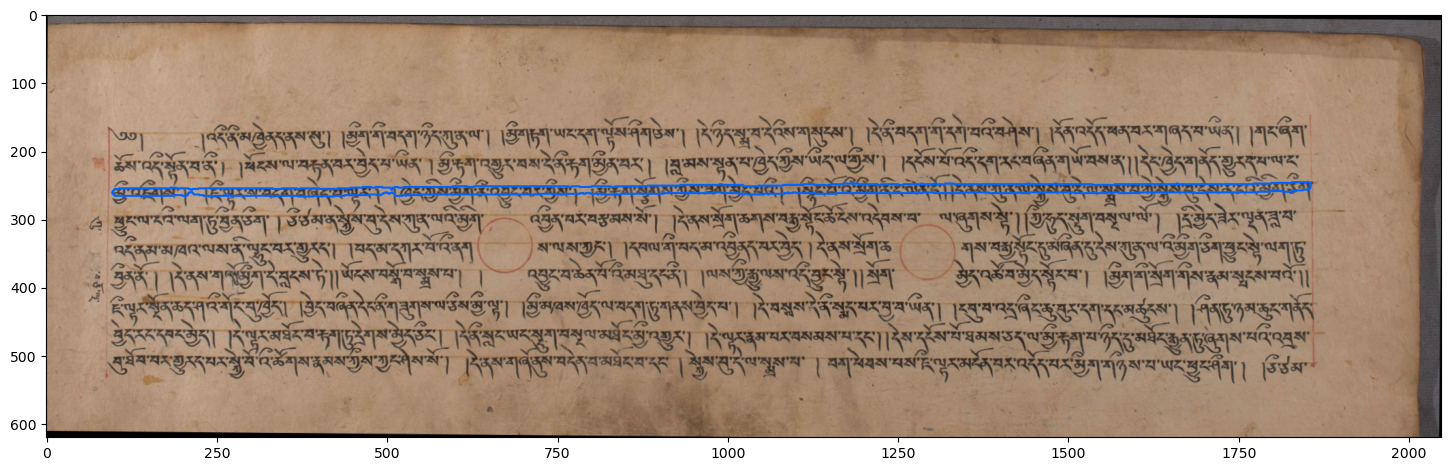

In [25]:
merged_line_prev = test_img.copy()
color = tuple([int(x) for x in COLOR_DICT["line"].split(",")])

for sorted_bcenter in sorted_bbox_centers[2]:
    print(sorted_bcenter)
    print(len(sorted_bbox_centers[1]))
    for line_data in layout_data.lines:
            if sorted_bcenter == line_data.center:
                print("found")
                cv2.drawContours(merged_line_prev,[line_data.contour],contourIdx=-1,color=color,thickness=2)

show_image(merged_line_prev)               

(969, 216)
found
(977, 257)
found
(966, 298)
found
(978, 429)
found
(976, 472)
found
(978, 513)
found


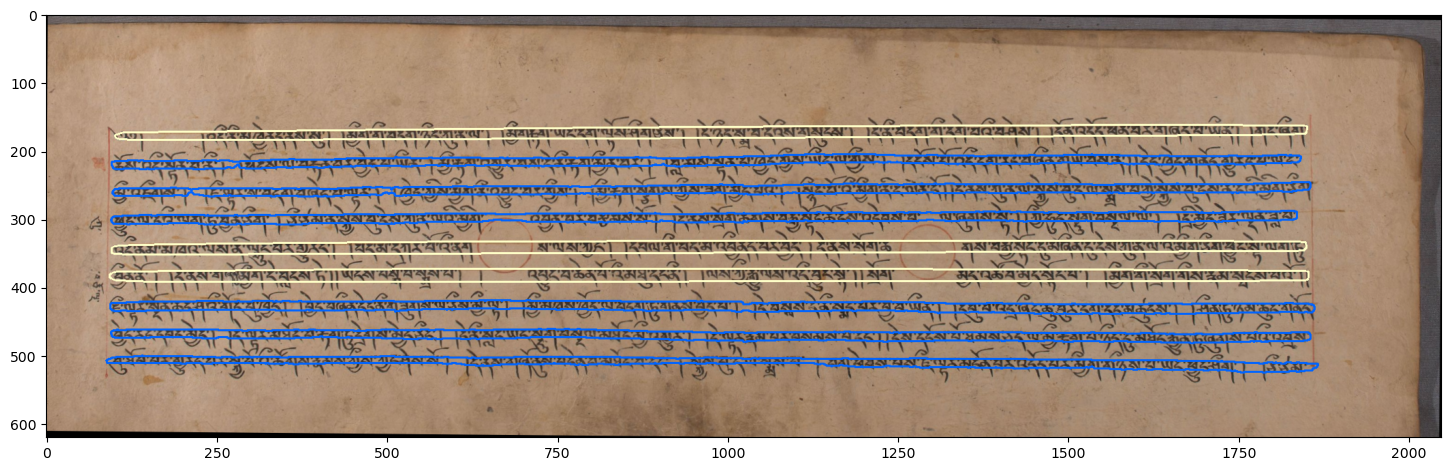

In [26]:
merged_line_prev = test_img.copy()
color = tuple([int(x) for x in COLOR_DICT["line"].split(",")])


contour_stack = []

for sorted_bcenter in sorted_bbox_centers:
    if len(sorted_bcenter) > 1:
        contour_stack = []
        
        for b_center in sorted_bcenter:
            for line_data in layout_data.lines:
                if b_center == line_data.center:
                    #bbox = line_data.bbox
                    #cv2.rectangle(merged_line_prev, (bbox.x, bbox.y), (bbox.x+bbox.w, bbox.y + bbox.h), color, 2)
                    #ctr = cv2.convexHull(ctr)
                    #cv2.drawContours(merged_line_prev,[line_data.contour],contourIdx=-1,color=color,thickness=-1,)
                    contour_stack.append(line_data.contour)

        stacked_contour = np.vstack(contour_stack)
        color = (255, 255, 200)
        ctr = cv2.convexHull(stacked_contour)
        cv2.drawContours(merged_line_prev, [ctr] ,contourIdx=-1,color=color,thickness=2)
        

    else:
        color = tuple([int(x) for x in COLOR_DICT["line"].split(",")])
        for _bcenter in sorted_bcenter:
            print(_bcenter)
            #print(len(sorted_bbox_centers[1]))
            for line_data in layout_data.lines:
                    if _bcenter == line_data.center:
                        print("found")
                        cv2.drawContours(merged_line_prev,[line_data.contour],contourIdx=-1,color=color,thickness=2)
    
show_image(merged_line_prev)

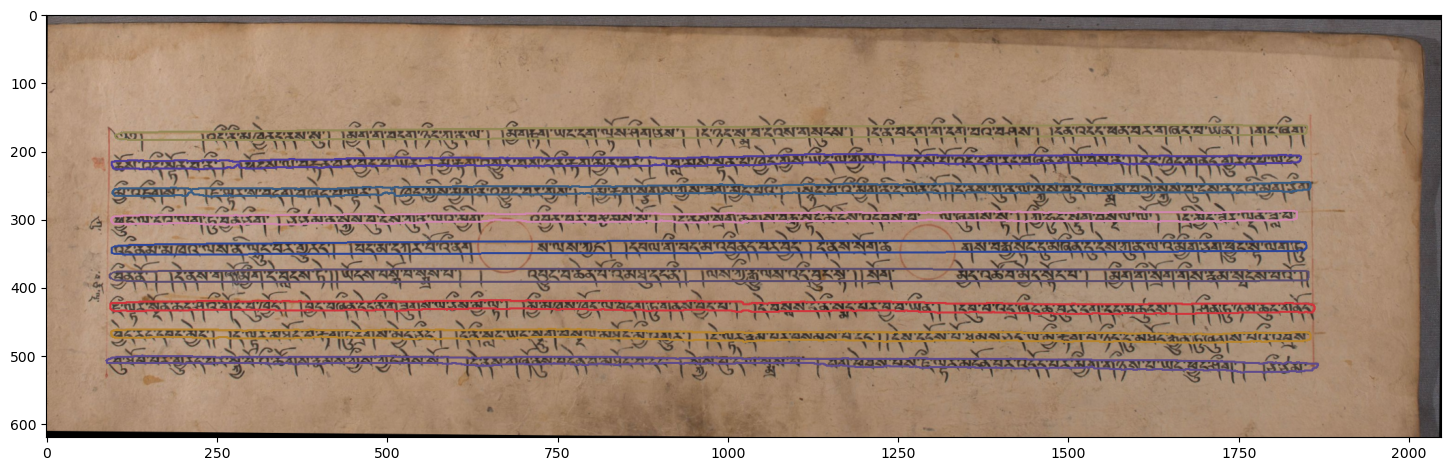

In [27]:
merged_line_prev = test_img.copy()

for line_data in new_lines:
    #color = tuple([int(x) for x in COLOR_DICT["line"].split(",")])
    color = get_random_color()
    #cv2.drawContours(merged_line_prev,[line_data.contour],contourIdx=-1,color=color,thickness=-1,)
    bbox = line_data.bbox
    #cv2.rectangle(merged_line_prev, (bbox.x, bbox.y), (bbox.x+bbox.w, bbox.y + bbox.h), color, 2)
    cv2.drawContours(merged_line_prev,[line_data.contour],contourIdx=-1,color=color,thickness=2,)
    
show_image(merged_line_prev)

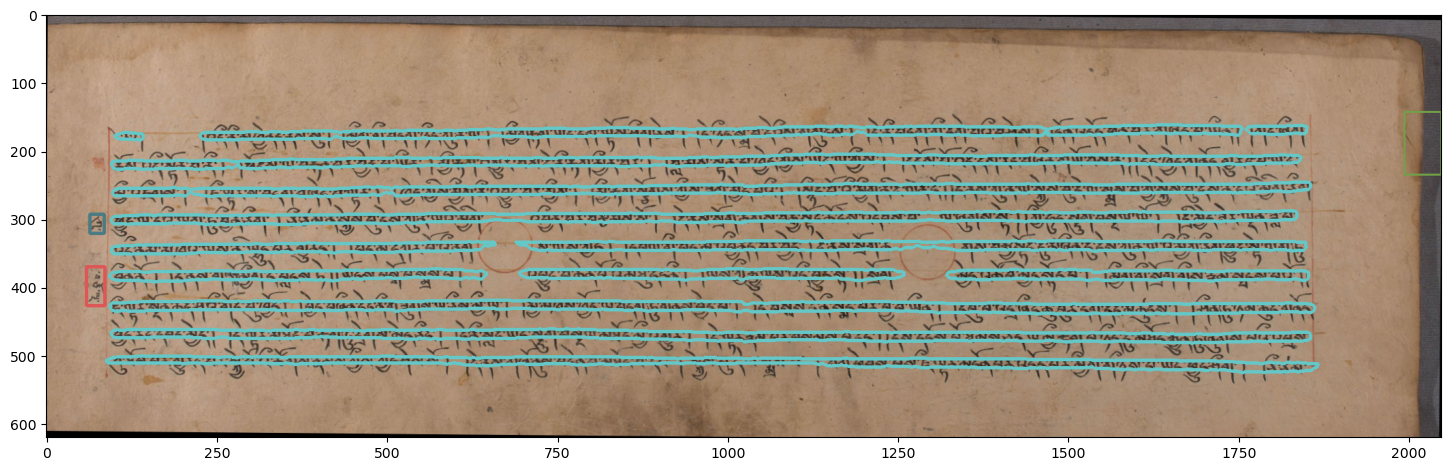

In [13]:
import random


preview2 = test_img.copy()

for bbox in layout_data.images:

    rand_r = random.randint(40, 255)
    rand_g = random.randint(40, 200)
    rand_b = random.randint(40, 220)
    color = (rand_r, rand_g, rand_b)

    cv2.rectangle(preview2 ,(bbox.x, bbox.y), (bbox.x+bbox.w, bbox.y + bbox.h), color, 2)


for bbox in layout_data.captions:
    rand_r = random.randint(40, 255)
    rand_g = random.randint(40, 200)
    rand_b = random.randint(40, 220)
    color = (rand_r, rand_g, rand_b)

    cv2.rectangle(preview2 ,(bbox.x, bbox.y), (bbox.x+bbox.w, bbox.y + bbox.h), color, 2)

for bbox in layout_data.margins:
    rand_r = random.randint(40, 255)
    rand_g = random.randint(40, 200)
    rand_b = random.randint(40, 220)
    color = (rand_r, rand_g, rand_b)

    cv2.rectangle(preview2 ,(bbox.x, bbox.y), (bbox.x+bbox.w, bbox.y + bbox.h), color, 4)

for line_data in layout_data.lines:
    contour = line_data.contour
    color = (100, 200, 200)

    cv2.drawContours(preview2,  [contour], -1, color, 3)
    #cv2.rectangle(preview2, (bbox.x, bbox.y), (bbox.x+bbox.w, bbox.y + bbox.h), color, 2)

show_image(preview2)

In [15]:
xml_exporter = PageXMLExporter(output_dir="Test/page")
xml_exporter.export(test_img, image_name, layout_data, [])

In [17]:
sub_dir = Path(f"D:/Github/OCR-Inference/Data/W2KG209989/I2KG210053")

_images = natsorted(glob(f"{sub_dir}/*.jpg"))

out_dir = os.path.join(sub_dir, "previews")
xml_out = os.path.join(sub_dir, "page")

create_dir(out_dir)
create_dir(xml_out)

xml_exporter = PageXMLExporter(output_dir=xml_out)

if len(_images) > 0:
    for idx, img_path in tqdm(enumerate(_images), total=len(_images)):
        img_name = os.path.basename(img_path).split(".")[0]
        pred_out = f"{out_dir}/{img_name}_prev.jpg"

        if not os.path.isfile(pred_out):
            _img = cv2.imread(img_path)
            res_img = resize_to_width(_img, target_width=2048)
            res_img = cv2.cvtColor(_img, cv2.COLOR_BGR2RGB)

            _prediction, class_image = predict_image(res_img)
            _prediction = _prediction.astype(np.uint8)
            _prediction = cv2.resize(_prediction, (_img.shape[1], _img.shape[0]))

            layout_data = generate_page_data(_prediction)

            xml_exporter.export(_img, img_name, layout_data, [])
            #cv2.imwrite(pred_out, test_pred_preview)

  0%|          | 0/548 [00:00<?, ?it/s]

  9%|▉         | 50/548 [03:40<36:37,  4.41s/it]


KeyboardInterrupt: 

In [ ]:
image_name

In [ ]:
work_dir = Path(f"D:/Github/OCR-Inference/Data/W2KG209989/I2KG210053")

for sub_dir in work_dir.iterdir():
    print(f"Directory: {sub_dir.name}")
    test_images = natsorted(glob(f"{sub_dir}/*.jpg"))

    out_dir = os.path.join(sub_dir, "previews")
    xml_out = os.path.join(sub_dir, "page")
    
    create_dir(out_dir)
    create_dir(xml_out)

    xml_exporter = PageXMLExporter(output_dir=xml_out)

    if len(test_images) > 0:
        for idx, img_path in tqdm(enumerate(test_images), total=len(test_images)):
            img_name = os.path.basename(img_path).split(".")[0]
            pred_out = f"{out_dir}/{img_name}_prev.jpg"

            if not os.path.isfile(pred_out):
                _img = cv2.imread(img_path)
                res_img = resize_to_width(_img, target_width=2048)
                res_img = cv2.cvtColor(_img, cv2.COLOR_BGR2RGB)

                _prediction, class_image = predict_image(res_img)
                _prediction = _prediction.astype(np.uint8)
                _prediction = cv2.resize(_prediction, (_img.shape[0], _img.shape[1]))
                layout_data = generate_page_data(_img.copy(), _prediction)

                xml_exporter.export(_img, img_name, layout_data, [])
                #cv2.imwrite(pred_out, test_pred_preview)

Directory: I2KG2100530004.jpg


FileNotFoundError: [WinError 3] Das System kann den angegebenen Pfad nicht finden: 'D:\\Github\\OCR-Inference\\Data\\W2KG209989\\I2KG210053\\I2KG2100530004.jpg\\previews'

In [14]:
test_data_dir = Path("D:\Data\LayoutAnalysis\AllWorks")

for sub_dir in test_data_dir.iterdir():
    #print(sub_dir)
    for img_dir in Path(sub_dir).iterdir():

        out_dir = os.path.join(img_dir, "previews_v2")
        create_dir(out_dir)
        test_images = natsorted(glob(f"{img_dir}/*.jpg"))
        
        if len(test_images) > 0:
            for idx, img_path in tqdm(enumerate(test_images), total=len(test_images)):
                img_name = os.path.basename(img_path).split(".")[0]
                pred_out = f"{out_dir}/{img_name}_prev.jpg"

                if not os.path.isfile(pred_out):   
                    _img = cv2.imread(img_path)
                    if (_img) is not None:
                        _img = resize_to_width(_img, target_width=2048)
                        _img = cv2.cvtColor(_img, cv2.COLOR_BGR2RGB)

                        _prediction, class_image = predict_image(_img)
                        _prediction = _prediction.astype(np.uint8)
                        _pred_preview = generate_page_data(_img, _prediction)

                        
                        cv2.imwrite(pred_out, _pred_preview)

 53%|█████▎    | 412/778 [03:15<02:53,  2.11it/s]


KeyboardInterrupt: 